### Nasser Hund – Lösung Schritt für Schritt

*44. Bundeswettbewerb Informatik (2025), 1. Runde, Aufgabe 3*

Hildas Hund Wuffi fühlt sich magisch durch Wasser angezogen und springt am liebsten in jeden Tümpel. Hilda wohnt in einem
Naherholungsgebiet, so dass bei dem täglichen Gassigang Wuffi sich an den vielen Seen austoben kann.

Wuffi ist derzeit leider erkrankt und soll nicht ins Wasser springen. Deswegen möchte Hilda ihren Hund beim Spaziergang an
eine Leine legen. Die Leine soll so kurz sein, dass Wuffi an keinem Punkt des Weges ins Wasser springen kann. Andererseits
soll sie aber auch möglichst lang sein, damit Wuffi viel Bewegungsfreiheit hat.

#### Aufgabe 3

Gegeben sei eine Karte des Naherholungsgebiets mit eingezeichneten Wegen (als Liniensegmente) und Seen (als Polygone).
Schreibe ein Programm für Hilda, das die längstmögliche Leinenlänge berechnet, so dass Wuffi beim Gassigehen nicht nass
werden kann, egal welche Wege Hilda nimmt.

Wende dein Programm mindestens auf alle Beispiele an, die du auf den BWINF-Webseiten findest, und dokumentiere die Ergebnisse.

#### Beispieldaten

Im Ordner `beispieldaten` stehen `hund01.txt` bis `hund06.txt`. Jede Datei hat diesen Aufbau:

1. Die Anzahl `k` der Wege.
2. `k` Zeilen, je eine mit `x1 y1 x2 y2`: die beiden Endpunkte eines Weges.
3. Die Anzahl `s` der Seen.
4. Für jeden See eine Zeile mit der Anzahl `n` seiner Eckpunkte, dann `n` Zeilen mit je `x y`. Die Eckpunkte stehen der Reihe nach
   (zum Beispiel im Uhrzeigersinn).

```
3
1 1 6 1
0 5 7 7
6 1 7 7
2
3
1 2
2 5
0 4
4
4 4
5 2
6 2
6 6
```

Das sind drei Wege und zwei Seen. Der erste See hat drei Eckpunkte, der zweite vier.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Die Aufgabe in Mathematik übersetzen:** Wuffi kann ins Wasser, wenn die Leine bis zum Ufer reicht. Die längste Leine, die nie
  reicht, ist also der **kleinste Abstand zwischen einem Punkt auf einem Weg und einem Punkt am Ufer**. Das Ufer besteht aus den
  Kanten der Seen, Wege und Ufer sind also beides Strecken. Gesucht ist der kleinste Abstand zwischen einer Weg-Strecke und
  einer Ufer-Strecke.
- **Abstand Punkt–Strecke:** Man bestimmt den Punkt der Strecke, der dem Punkt am nächsten liegt (den *Lotfußpunkt*, wenn er auf
  der Strecke liegt, sonst einen Endpunkt) und misst den Abstand.
- **Abstand Strecke–Strecke:** Wenn sich zwei Strecken nicht kreuzen, liegt der kleinste Abstand immer an einem **Endpunkt** einer
  der beiden Strecken. Man muss also nur die vier Abstände „Endpunkt zur anderen Strecke“ vergleichen.
- **Alle Paare durchprobieren:** Jede Weg-Strecke mit jeder Ufer-Strecke vergleichen und das Minimum merken. Bei den großen
  Beispielen sind das fast drei Millionen Paare.
- **Eine billige Vorprüfung:** Liegen die Umrechtecke zweier Strecken schon weiter auseinander als der beste bisherige Abstand,
  muss man den genauen Abstand gar nicht erst ausrechnen.

**Nützliche Funktionen und Bibliotheken**
- `math.sqrt` für die Wurzel, `min` und `max`
- Tupel `(x, y)` für Punkte, Listen von Listen für die Seen
- `matplotlib.pyplot` für die Zeichnung (optional)

## Die Idee

1. Die Karte einlesen: Wege als Paare von Punkten, Seen als Listen von Eckpunkten.
2. Aus den Seen die **Uferkanten** machen: Je zwei aufeinanderfolgende Eckpunkte bilden eine Kante, und vom letzten Eckpunkt
   geht eine Kante zurück zum ersten.
3. Eine Funktion für den **Abstand eines Punktes zu einer Strecke** schreiben (mit dem nächsten Punkt der Strecke).
4. Daraus den **Abstand zweier Strecken** machen: vier Endpunkt-Abstände, der kleinste gilt.
5. **Alle Paare** aus Weg und Uferkante durchgehen und den kleinsten Abstand merken.
6. Mit einer **Vorprüfung** viele Paare gleich überspringen, damit auch die großen Beispiele schnell gehen.

## Schritt 1: Die Karte einlesen

Ein Punkt ist ein Tupel `(x, y)`. Ein Weg ist ein Paar von Punkten, ein See eine Liste seiner Eckpunkte. Die Koordinaten lesen wir
als Kommazahlen (`float`), weil damit später die Abstände berechnet werden.

In [ ]:
def lies_karte(dateiname):
    with open(dateiname, encoding='utf-8') as f:
        zeilen = []
        for zeile in f.read().splitlines():
            if zeile.split():                          # leere Zeilen überspringen
                zeilen.append(zeile.split())
    i = 0
    k = int(zeilen[i][0])
    i = i + 1
    wege = []
    for j in range(k):
        x1, y1, x2, y2 = zeilen[i]
        wege.append(((float(x1), float(y1)), (float(x2), float(y2))))
        i = i + 1
    s = int(zeilen[i][0])
    i = i + 1
    seen = []
    for j in range(s):
        n = int(zeilen[i][0])
        i = i + 1
        eckpunkte = []
        for m in range(n):
            eckpunkte.append((float(zeilen[i][0]), float(zeilen[i][1])))
            i = i + 1
        seen.append(eckpunkte)
    return wege, seen


wege, seen = lies_karte('beispieldaten/hund01.txt')
print('Wege:', wege)
print('Seen:', seen)

Wege: [((13.0, 18.0), (29.0, 8.0)), ((29.0, 8.0), (31.0, 19.0)), ((31.0, 19.0), (41.0, 30.0)), ((41.0, 30.0), (17.0, 32.0)), ((17.0, 32.0), (13.0, 18.0))]
Seen: [[(23.0, 19.0), (31.0, 25.0), (21.0, 27.0)]]


`hund01.txt` hat 5 Wege, die zusammen ein Fünfeck um den See bilden, und einen See mit drei Eckpunkten.

## Schritt 2: Die Uferkanten

Zwischen zwei aufeinanderfolgenden Eckpunkten eines Sees verläuft ein Stück Ufer. Das Ufer ist ein **geschlossener** Linienzug:
Auch vom letzten Eckpunkt zurück zum ersten gibt es eine Kante. Mit `(i + 1) % n` wird nach dem letzten Eckpunkt wieder der erste.

In manchen Beispieldateien steht der erste Eckpunkt am Ende noch einmal (zum Beispiel in `hund03.txt`). Dann entsteht zusätzlich
eine Kante der Länge 0, also ein einzelner Punkt. Das ist harmlos, wenn unsere Abstandsfunktion damit klarkommt (Schritt 3).

In [ ]:
def ufer_kanten(seen):
    kanten = []
    for eckpunkte in seen:
        n = len(eckpunkte)
        for i in range(n):
            kanten.append((eckpunkte[i], eckpunkte[(i + 1) % n]))
    return kanten


kanten = ufer_kanten(seen)
for k in kanten:
    print(k)

((23.0, 19.0), (31.0, 25.0))
((31.0, 25.0), (21.0, 27.0))
((21.0, 27.0), (23.0, 19.0))


## Schritt 3: Abstand eines Punktes zu einer Strecke

Gegeben sind ein Punkt `p` und eine Strecke von `a` nach `b`. Wir suchen den **Punkt der Strecke, der `p` am nächsten liegt**. Alle
Punkte der Strecke kann man als `a + t · (b − a)` mit `t` zwischen 0 und 1 schreiben (`t = 0` ist `a`, `t = 1` ist `b`).

Das `t` des **Lotfußpunkts** (der Punkt auf der Geraden durch `a` und `b`, von dem aus `p` senkrecht über der Geraden steht) ist

`t = ((p − a) · (b − a)) / |b − a|²`,

wobei der Punkt im Zähler das Skalarprodukt `(px − ax)·(bx − ax) + (py − ay)·(by − ay)` ist und im Nenner das Quadrat der Länge der
Strecke steht. Liegt `t` zwischen 0 und 1, ist der Lotfußpunkt auf der Strecke und der nächste Punkt. Ist `t` kleiner als 0, ist
`a` der nächste Punkt, ist `t` größer als 1, ist es `b`. Das erreichen wir einfach mit `t = max(0, min(1, t))`.

Hat die Strecke die Länge 0 (`a` und `b` sind gleich), wäre der Nenner 0. Dann ist `a` der nächste Punkt.

Der Abstand ist dann die Länge der Verbindung von `p` zum nächsten Punkt (Satz des Pythagoras). Wir geben den nächsten Punkt mit
zurück, denn damit können wir später auch zeigen, **wo** die kürzeste Verbindung liegt.

In [ ]:
from math import sqrt


def abstand(p, q):
    return sqrt((p[0] - q[0]) ** 2 + (p[1] - q[1]) ** 2)


def naechster_punkt(p, a, b):
    """Punkt der Strecke ab, der p am nächsten liegt."""
    dx = b[0] - a[0]
    dy = b[1] - a[1]
    laenge2 = dx * dx + dy * dy
    if laenge2 == 0:                                   # a und b sind derselbe Punkt
        return a
    t = ((p[0] - a[0]) * dx + (p[1] - a[1]) * dy) / laenge2
    t = max(0, min(1, t))                              # nicht über die Endpunkte hinaus
    return (a[0] + t * dx, a[1] + t * dy)


# Strecke von (0, 0) nach (4, 0)
a = (0, 0)
b = (4, 0)
for p in [(2, 3), (-1, 1), (6, 0), (1, 0)]:
    q = naechster_punkt(p, a, b)
    print(p, '-> nächster Punkt', q, ', Abstand', abstand(p, q))

(2, 3) -> nächster Punkt (2.0, 0.0) , Abstand 3.0
(-1, 1) -> nächster Punkt (0, 0) , Abstand 1.4142135623730951
(6, 0) -> nächster Punkt (4, 0) , Abstand 2.0
(1, 0) -> nächster Punkt (1.0, 0.0) , Abstand 0.0


Zur Probe mit der Strecke auf der x-Achse: Der Punkt `(2, 3)` liegt senkrecht über der Strecke, der Abstand ist 3.
Der Punkt `(−1, 1)` liegt links neben der Strecke, nächster Punkt ist `a = (0, 0)` mit Abstand `√2`. Der Punkt `(6, 0)` liegt rechts
von der Strecke auf deren Verlängerung, nächster Punkt ist `b`. Der Punkt `(1, 0)` liegt auf der Strecke, der Abstand ist 0.

## Schritt 4: Abstand zweier Strecken

Wenn sich zwei Strecken nicht kreuzen, ist ihr kleinster Abstand immer der Abstand **eines Endpunkts zur anderen Strecke**. Warum?
Wäre der kürzeste Abstand zwischen zwei Punkten im Inneren der Strecken, müssten die beiden Strecken parallel sein. Dann kann man
beide Punkte parallel verschieben, bis einer von ihnen ein Endpunkt ist, ohne dass der Abstand größer wird.

Das nehmen wir für die Aufgabe an: Laut Aufgabe schneiden sich Strecken höchstens in ihren Endpunkten. Wir berechnen also vier Abstände,
Endpunkt `c` und `d` der einen zur Strecke `ab`, Endpunkt `a` und `b` zur Strecke `cd`, und nehmen den kleinsten. Dazu merken wir uns
das Paar der beiden Punkte, die diesen Abstand haben.

In [ ]:
def abstand_strecken(a, b, c, d):
    """Kleinster Abstand der Strecken ab und cd. Ergebnis: (Abstand, Punkt auf der ersten, Punkt auf der zweiten Strecke)."""
    bestes = None
    # Endpunkte von cd gegen die Strecke ab
    for p in [c, d]:
        q = naechster_punkt(p, a, b)
        if bestes is None or abstand(p, q) < bestes[0]:
            bestes = (abstand(p, q), q, p)
    # Endpunkte von ab gegen die Strecke cd
    for p in [a, b]:
        q = naechster_punkt(p, c, d)
        if abstand(p, q) < bestes[0]:
            bestes = (abstand(p, q), p, q)
    return bestes


print(abstand_strecken((0, 0), (4, 0), (1, 2), (3, 5)))    # parallel versetzt, Abstand 2 von (1, 2)
print(abstand_strecken((0, 0), (4, 0), (6, 1), (8, 3)))    # seitlich versetzt, kürzester Abstand von (4, 0) zu (6, 1)

(2.0, (1.0, 0.0), (1, 2))
(2.23606797749979, (4, 0), (6, 1))


## Schritt 5: Alle Paare durchprobieren

Wir gehen jeden Weg mit jeder Uferkante durch und merken uns das Paar mit dem kleinsten Abstand. In `paare` zählen wir, wie
viele Paare angeschaut wurden.

In [ ]:
def leinenlaenge(wege, kanten):
    bestes = None
    for a, b in wege:
        for c, d in kanten:
            ergebnis = abstand_strecken(a, b, c, d)
            if bestes is None or ergebnis[0] < bestes[0]:
                bestes = ergebnis
    return bestes


for nr in ['01', '02', '03', '04']:
    wege, seen = lies_karte('beispieldaten/hund' + nr + '.txt')
    kanten = ufer_kanten(seen)
    laenge, auf_weg, am_ufer = leinenlaenge(wege, kanten)
    print('hund' + nr + '.txt:', len(wege), 'Wege,', len(kanten), 'Uferkanten, Paare:', len(wege) * len(kanten))
    print('  Leine höchstens', round(laenge, 6), ' zwischen', auf_weg, 'und', am_ufer)

hund01.txt: 5 Wege, 3 Uferkanten, Paare: 15
  Leine höchstens 4.036037  zwischen (33.98642533936652, 22.285067873303166) und (31.0, 25.0)
hund02.txt: 9 Wege, 14 Uferkanten, Paare: 126
  Leine höchstens 4.209878  zwischen (21.676923076923075, 20.415384615384617) und (25.0, 23.0)
hund03.txt: 30 Wege, 73 Uferkanten, Paare: 2190
  Leine höchstens 2.236068  zwischen (99.0, 91.0) und (100.0, 93.0)
hund04.txt: 22 Wege, 17 Uferkanten, Paare: 374
  Leine höchstens 1.671258  zwischen (51.44827586206897, 51.37931034482759) und (53.0, 52.0)


Die kürzeste Verbindung geht immer von einem Punkt auf einem Weg zu einem Punkt am Ufer. Bei `hund01.txt` ist die Leine höchstens
4,036 lang. Der Punkt am Ufer ist der Eckpunkt `(31, 25)` des Sees, der Punkt auf dem Weg liegt mitten auf der Wegstrecke von
`(31, 19)` nach `(41, 30)`. Die Lösungshinweise nennen genau dieses Punktepaar.

## Schritt 6: Die Karte als Bild

Zur Kontrolle zeichnen wir die Karten: Wege blau, Seen als gefüllte Polygone und die kürzeste Verbindung rot. Dann sieht man, ob
das Ergebnis plausibel ist.

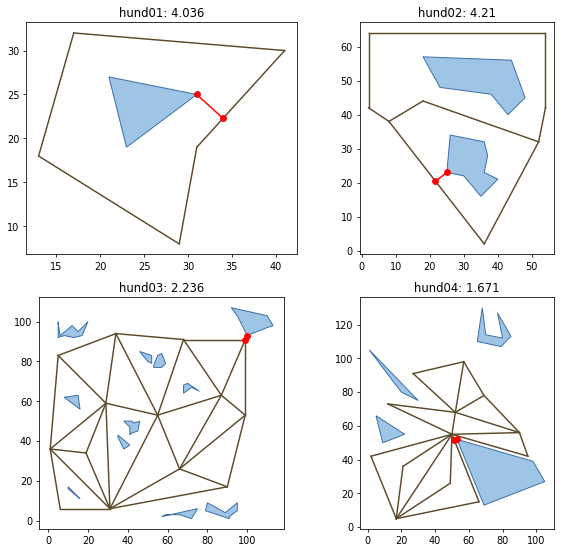

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon


def zeichne(wege, seen, verbindung, titel, achse):
    for eckpunkte in seen:
        achse.add_patch(Polygon(eckpunkte, closed=True, facecolor='#9ec5e6', edgecolor='#3a6ea5'))
    for a, b in wege:
        achse.plot([a[0], b[0]], [a[1], b[1]], color='#5c4a2a')
    laenge, p, q = verbindung
    achse.plot([p[0], q[0]], [p[1], q[1]], 'o-', color='red')
    achse.set_title(titel + ': ' + str(round(laenge, 3)))
    achse.set_aspect('equal')
    achse.autoscale()


fig, achsen = plt.subplots(2, 2, figsize=(9, 8))
for achse, nr in zip(achsen.flatten(), ['01', '02', '03', '04']):
    wege, seen = lies_karte('beispieldaten/hund' + nr + '.txt')
    verbindung = leinenlaenge(wege, ufer_kanten(seen))
    zeichne(wege, seen, verbindung, 'hund' + nr, achse)
plt.tight_layout()
plt.show()

## Schritt 7: Die großen Beispiele schneller machen

`hund05.txt` hat 899 Wege und fast 3000 Uferkanten, das sind etwa 2,7 Millionen Paare. Jedes Paar bedeutet vier
Punkt-Strecke-Abstände. In Python dauert das gut zehn Sekunden, im Browser länger. Geht das schneller?

Fast alle Paare liegen weit voneinander entfernt und können nie der kleinste Abstand sein. Das sieht man schon an einer einfachen
Überlegung: Jede Strecke liegt in ihrem **Umrechteck** (kleinster und größter `x`- und `y`-Wert). Der Abstand der beiden Rechtecke
ist höchstens der Abstand der Strecken, also eine **untere Grenze**. Ist die schon mindestens so groß wie der beste bisher gefundene
Abstand, kann das Paar nicht mehr besser sein, und wir überspringen es.

`luecke` gibt den Abstand zweier Intervalle auf einer Achse zurück (0, wenn sie sich überlappen). Der Abstand der Rechtecke ist dann
die Wurzel aus der Summe der Quadrate der Lücken in `x` und `y`. Wir vergleichen die Quadrate und sparen uns die Wurzel.
In `genau` zählen wir, bei wie vielen Paaren trotzdem der genaue Abstand berechnet werden musste.

In [ ]:
def luecke(klein1, gross1, klein2, gross2):
    """Abstand der Intervalle [klein1, gross1] und [klein2, gross2] (0, wenn sie sich überlappen)."""
    if gross1 < klein2:
        return klein2 - gross1
    if gross2 < klein1:
        return klein1 - gross2
    return 0


genau = [0]


def leinenlaenge_schnell(wege, kanten):
    bestes = None
    beste_laenge = float('inf')
    for a, b in wege:
        for c, d in kanten:
            lx = luecke(min(a[0], b[0]), max(a[0], b[0]), min(c[0], d[0]), max(c[0], d[0]))
            if lx >= beste_laenge:
                continue                                       # schon in x zu weit weg
            ly = luecke(min(a[1], b[1]), max(a[1], b[1]), min(c[1], d[1]), max(c[1], d[1]))
            if lx * lx + ly * ly >= beste_laenge * beste_laenge:
                continue                                       # Umrechtecke zu weit weg
            genau[0] = genau[0] + 1
            ergebnis = abstand_strecken(a, b, c, d)
            if ergebnis[0] < beste_laenge:
                bestes = ergebnis
                beste_laenge = ergebnis[0]
    return bestes


for nr in ['03', '05']:
    wege, seen = lies_karte('beispieldaten/hund' + nr + '.txt')
    kanten = ufer_kanten(seen)
    genau[0] = 0
    laenge = leinenlaenge_schnell(wege, kanten)[0]
    print('hund' + nr + '.txt:', len(wege) * len(kanten), 'Paare, davon genau berechnet:', genau[0], ', Leine', round(laenge, 6))

hund03.txt: 2190 Paare, davon genau berechnet: 139 , Leine 2.236068
hund05.txt: 2693404 Paare, davon genau berechnet: 16479 , Leine 50.32035


Bei `hund05.txt` müssen nur etwa 16 000 von 2,7 Millionen Paaren genau berechnet werden, und das Ergebnis bleibt dasselbe.

## Schritt 8: Alle Beispiele

Für jedes Beispiel geben wir die längste Leine mit sechs Nachkommastellen aus, dazu das Punktepaar, das den kleinsten Abstand hat.

In [ ]:
ergebnisse = {}
for nr in range(1, 7):
    dateiname = 'beispieldaten/hund0' + str(nr) + '.txt'
    wege, seen = lies_karte(dateiname)
    kanten = ufer_kanten(seen)
    laenge, auf_weg, am_ufer = leinenlaenge_schnell(wege, kanten)
    ergebnisse[nr] = (laenge, auf_weg, am_ufer)
    print(dateiname + ':', len(wege), 'Wege,', len(seen), 'Seen,', len(kanten), 'Uferkanten')
    print('  längste Leine:', round(laenge, 6))
    print('  Punkt auf dem Weg:', auf_weg, ' Punkt am Ufer:', am_ufer)

beispieldaten/hund01.txt: 5 Wege, 1 Seen, 3 Uferkanten
  längste Leine: 4.036037
  Punkt auf dem Weg: (33.98642533936652, 22.285067873303166)  Punkt am Ufer: (31.0, 25.0)
beispieldaten/hund02.txt: 9 Wege, 2 Seen, 14 Uferkanten
  längste Leine: 4.209878
  Punkt auf dem Weg: (21.676923076923075, 20.415384615384617)  Punkt am Ufer: (25.0, 23.0)
beispieldaten/hund03.txt: 30 Wege, 11 Seen, 73 Uferkanten
  längste Leine: 2.236068
  Punkt auf dem Weg: (99.0, 91.0)  Punkt am Ufer: (100.0, 93.0)
beispieldaten/hund04.txt: 22 Wege, 4 Seen, 17 Uferkanten
  längste Leine: 1.671258
  Punkt auf dem Weg: (51.44827586206897, 51.37931034482759)  Punkt am Ufer: (53.0, 52.0)
beispieldaten/hund05.txt: 899 Wege, 400 Seen, 2996 Uferkanten
  längste Leine: 50.32035
  Punkt auf dem Weg: (85194.81557780845, 96077.08987741536)  Punkt am Ufer: (85180.0, 96029.0)
beispieldaten/hund06.txt: 900 Wege, 200 Seen, 1524 Uferkanten
  längste Leine: 199.572502
  Punkt auf dem Weg: (78210.27511201614, 79189.49961184931)  Pu

**Ergebnis:** Die Längen stimmen mit der Tabelle der offiziellen Lösungshinweise überein:

| Beispiel | längste Leine |
|---|---|
| hund01 | 4,036037 |
| hund02 | 4,209878 |
| hund03 | 2,236068 |
| hund04 | 1,671258 |
| hund05 | 50,320350 |
| hund06 | 199,572502 |

Bei `hund03.txt` ist die Leine genau `√5 ≈ 2,236`: Der Punkt `(99, 91)` auf dem Weg und der Punkt `(100, 93)` am Ufer sind einen Schritt
in `x` und zwei Schritte in `y` voneinander entfernt. Bei `hund04.txt` ist das Punktepaar nicht eindeutig: Es liegt auf zwei parallelen Strecken, ein
Punktepaar ist so gut wie das andere. Die Länge ändert das nicht.

## Für Neugierige

**Gleitkommazahlen:** Die Abstände sind Kommazahlen mit Rundungsfehlern in den letzten Stellen. Die Aufgabe erlaubt deshalb eine
kleine Abweichung (zum Beispiel bei `hund01.txt` zwischen 4,035 und 4,037). Vergleichen sollte man Kommazahlen nie mit `==`,
sondern mit einer kleinen Toleranz, zum Beispiel `abs(x - y) < 0.000001`. Auch unser Vorfilter ist deshalb vorsichtig: Er
überspringt ein Paar nur, wenn die untere Grenze mindestens so groß ist wie der beste Abstand.

**Wege im Wasser und Kreuzungen:** Wir haben angenommen, dass sich Strecken höchstens in ihren Endpunkten berühren und dass Wege
nicht im See verlaufen. Sonst wäre die Leine 0 lang. Kreuzen sich Strecken, ist der Abstand 0, und die vier Endpunkt-Abstände reichen
nicht mehr, denn im Inneren der Strecken gäbe es einen Schnittpunkt.

**Noch schneller:** Die Lösungshinweise beschreiben ein Verfahren mit Laufzeit `n · log n` statt `n²`: Man berechnet das
*Voronoi-Diagramm* aller Strecken und muss dann nur noch Strecken vergleichen, die im Diagramm Nachbarn sind und aus verschiedenen
Mengen (Weg und Ufer) stammen. Das ist aufwendig zu programmieren und wird in der Aufgabe nicht erwartet.

**Fertige Bibliotheken:** In Python gibt es das Modul `shapely`: Mit `LineString(...).distance(Polygon(...).exterior)` erhält man
Abstände fertig berechnet. Die Aufgabe erlaubt solche Bibliotheken, aber man muss sie in der Dokumentation erwähnen und begründen.
Hier haben wir lieber selbst gerechnet, weil man dabei die Geometrie versteht.